In [2]:
# %matplotlib widget
import os
import logging
from glob import glob
from datetime import datetime
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.backends.backend_pdf import PdfPages

from astropy.io import fits
from astropy.time import Time
from astropy.stats import sigma_clipped_stats

from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from scipy import signal

from rich.table import Table
from rich.console import Console

In [3]:
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.dpi': 100,
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 20,
    'axes.labelpad': 10,
    'axes.linewidth': 1.2,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'legend.fontsize': 12,
})

In [5]:
# instead of print statements, I am using logger, to classify the messages into INFO, WARNING, ERROR. 
def get_logger(log_file: str) -> logging.Logger:
    logger = logging.getLogger(__name__)
    logger.setLevel(logging.INFO)
    logger.handlers.clear()
    
    formatter = logging.Formatter("[%(levelname)s at %(asctime)s] — %(message)s")
    
    fh = logging.FileHandler(log_file)
    fh.setFormatter(formatter)
    logger.addHandler(fh)
    
    sh = logging.StreamHandler()  # prints to notebook
    sh.setFormatter(formatter)
    logger.addHandler(sh)
    
    return logger, fh

# I will use this function to now open a log file and write all the messages to it, while also printing to the notebook.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
if not os.path.exists("logs"):
    os.makedirs("logs")
logger, fh = get_logger(f"logs/run_{timestamp}.log")
logger.info("Logger initialized successfully")

[INFO at 2026-09-02 17:39:14,287] — Logger initialized successfully


In [6]:
arcs_dir = "/hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis"

In [7]:
# Search for all downloaded FITS files recursively
def get_all_fits_files(directory: str) -> list:
    """
    Recursively searches for all FITS files in the given directory and its subdirectories.
    """
    if not os.path.exists(directory):
        logger.error(f"Directory does not exist: {directory}")
        return []
    return glob(os.path.join(directory, "**/*.fits*"), recursive=True)




# a function to filter out bad files based on some criteria, such as file size or header keywords.
# filter the arc files
def filter_fits_files(file_list):
    """
    Removes:
    - ARC files from 'triplespec' instrument
    - ARC files which are standard AEON night calibrations. they have the header key OBJECT == 'ARC'

    Keeps:
    - ARC files that are taken before and after the science exposures, which are the ones relevant for this study.
    
    Inputs:
        file_list: list of .fits file paths
    Outputs:
        good_files: list of filtered file paths
    """
    good_files = []
    
    for file in file_list:
        logger.info(f"Processing file: {file}")
        try:
            with fits.open(file) as hdul:
                header = hdul[1].header
                
                instrume = header.get("INSTRUME", "").lower()
                object_val = header.get("OBJECT", "").strip().upper()
                
                # Not considering arcs from triplespec, as they are not relevant for this study.
                if instrume == "triplespec":
                    logger.warning(f"Skipping {file} — INSTRUME: {header['INSTRUME']}")
                    continue
                
                # # I am skipping arc files that are a part of the standard AEON night calibrations. They have a particular header keyword that identifies them as arcs fromt the standard AEON calibrations. For this study, we don't need them as we are mostly instrested in arcs taken before and after the science exposures. 
                # if object_val == "ARC":
                #     logger.warning(f"Skipping {file} — OBJECT: {header['OBJECT']}")
                #     continue
                
                good_files.append(file)

        #just in case, if any file is corrupt.  
        except Exception as e:
            logger.error(f"Skipping {file} — could not read: {e}")
            continue
    
    if len(good_files) == 0:
        logger.warning("No good files found after filtering.")
    else:
        logger.info(f"Found {len(good_files)} good files after filtering.")
    return good_files

In [8]:
# Now I will get all the fits files from both pre and post maintenance directories, and then filter them using the above function.
all_arcs  = get_all_fits_files(arcs_dir)  # Assuming all files in arcs_dir are pre-maintenance files


good_arcs = filter_fits_files(all_arcs) #arc files that are relevant for this study, taken before the maintenance

[INFO at 2026-09-02 17:41:17,974] — Processing file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0002_Calibration-Star_13-04-2025_comp.fits.fz
[INFO at 2026-09-02 17:41:17,995] — Processing file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0003_Calibration-Star_13-04-2025_comp.fits.fz
[INFO at 2026-09-02 17:41:18,015] — Processing file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0006_Calibration-Star_13-04-2025_comp.fits.fz
[INFO at 2026-09-02 17:41:18,025] — Processing file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0061_Calibration-Star_13-07-2025_comp.fits.fz
[INFO at 2026-09-02 17:41:18,035] — Processing file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0062_Calibration-Star_13-07-2025_comp.fits.fz
[INFO at 2026-09-02 17:41:18,044] — Processing file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0062_Calibration-Star_24-01-2025_comp.fits.fz
[INFO at 2026-09

In [10]:
logger.info(f'Keeping {len(good_arcs)}/{len(all_arcs)} files for analysis.')

[INFO at 2026-09-02 17:41:59,876] — Keeping 1013/1632 files for analysis.


In [29]:
def get_specific_grating_arc(good_arcs, grating_name):
    """
    Filters the good arcs to only include those taken with the specified grating mode.
    
    Inputs:
        good_arcs: list of filtered .fits file paths
        grating_name: WAVMODE string to filter on, e.g. "400_M1"
    Outputs:
        specific_grating_arcs: list of .fits file paths taken with grating_name
    """
    specific_grating_arcs = []
    
    for file in good_arcs:
        try:
            header, data = read_fits_file(file)
            grating = header.get("WAVMODE", "").strip().upper()
            
            if grating == grating_name.upper():
                specific_grating_arcs.append(file)
            else:
                logger.warning(f"Skipping {file} — WAVMODE: {header.get('WAVMODE')}")
        
        except Exception as e:
            logger.error(f"Skipping {file} — could not read: {e}")
            continue
    
    if len(specific_grating_arcs) == 0:
        logger.warning(f"No {grating_name} arcs found after filtering.")
    else:
        logger.info(f"Found {len(specific_grating_arcs)} {grating_name} arcs after filtering.")
    
    return specific_grating_arcs

In [31]:
arcs_400m1 = get_specific_grating_arc(good_arcs, grating_name="400_M1")
arcs_400m2 = get_specific_grating_arc(good_arcs, grating_name="400_M2")

[WARNING at 2026-09-02 17:59:59,733] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0002_Calibration-Star_13-04-2025_comp.fits.fz — WAVMODE: 2100_6507A


[WARNING at 2026-09-02 17:59:59,797] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0003_Calibration-Star_13-04-2025_comp.fits.fz — WAVMODE: 1200_CaNIR
[WARNING at 2026-09-02 17:59:59,859] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0006_Calibration-Star_13-04-2025_comp.fits.fz — WAVMODE: 1200_CaNIR_6300A
[WARNING at 2026-09-02 17:59:59,958] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0062_Calibration-Star_13-07-2025_comp.fits.fz — WAVMODE: 400_M2
[WARNING at 2026-09-02 18:00:00,056] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0063_Calibration-Star_24-01-2025_comp.fits.fz — WAVMODE: 400_M2
[WARNING at 2026-09-02 18:00:00,118] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0065_Calibration-Star_13-07-2025_comp.fits.fz — WAVMODE: 2100_5000A
[WARNING at 2026-09-02 18:00:00,178] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soa

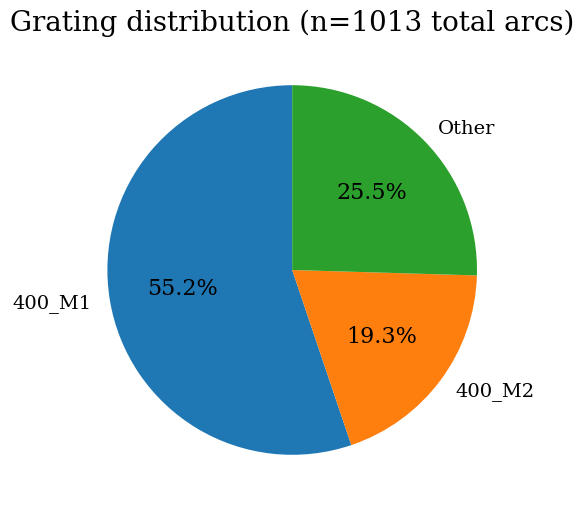

In [32]:
import matplotlib.pyplot as plt

n_400m1 = len(arcs_400m1)
n_400m2 = len(arcs_400m2)
n_total = len(good_arcs)
n_other = n_total - n_400m1 - n_400m2

labels = ["400_M1", "400_M2", "Other"]
sizes = [n_400m1, n_400m2, n_other]

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=90)
ax.set_title(f"Grating distribution (n={n_total} total arcs)")
plt.show()

In [36]:
header, data = read_fits_file(arcs_400m1[0])

print("Data shape:", data.shape)
print("DATASEC:", header.get("DATASEC"))
print("TRIMSEC:", header.get("TRIMSEC"))
print("BIASSEC:", header.get("BIASSEC"))
print("CCDSEC:", header.get("CCDSEC"))
print("NAXIS1, NAXIS2:", header.get("NAXIS1"), header.get("NAXIS2"))

AttributeError: 'dict' object has no attribute 'shape'

In [37]:
print(type(data))
print(data.keys() if isinstance(data, dict) else "not a dict")

<class 'dict'>
dict_keys([0, 1])


In [38]:
print("data[0]:", type(data[0]), getattr(data[0], "shape", None))
print("data[1]:", type(data[1]), getattr(data[1], "shape", None))

data[0]: <class 'NoneType'> None
data[1]: <class 'numpy.ndarray'> (948, 2071)


In [39]:
image = data[1]
trimmed = image[1:948, 25:2055]

print("Full shape:", image.shape)
print("Trimmed shape:", trimmed.shape)

Full shape: (948, 2071)
Trimmed shape: (947, 2030)


In [40]:
spec = np.sum(trimmed, axis=0).astype(np.float64)
print(spec.shape)

(2030,)


In [41]:
def extract_1d_arc_spectrum(filepath):
    """
    Extracts a 1D arc spectrum from a SOAR fits.fz file by trimming the
    overscan region (using TRIMSEC) and summing along the spatial axis.
    
    Inputs:
        filepath: path to a .fits.fz arc file
    Outputs:
        spec: 1D numpy array, summed spectrum along columns
    """
    header, data = read_fits_file(filepath)
    image = data[1]
    trimmed = image[1:948, 25:2055]
    spec = np.sum(trimmed, axis=0).astype(np.float64)
    return spec

In [42]:
trimsecs = set()
for f in arcs_400m1:
    header, data = read_fits_file(f)
    trimsecs.add(header.get("TRIMSEC"))

print(trimsecs)

{'[1:3096,1:3096]', '[26:2055,2:948]'}


In [43]:
arcs_400m1_filtered = []

for f in arcs_400m1:
    header, data = read_fits_file(f)
    trimsec = header.get("TRIMSEC")
    if trimsec == "[26:2055,2:948]":
        arcs_400m1_filtered.append(f)
    else:
        logger.warning(f"Skipping {f} — unexpected TRIMSEC: {trimsec}")

print(f"Kept {len(arcs_400m1_filtered)}/{len(arcs_400m1)} files with matching TRIMSEC")

[WARNING at 2026-09-02 20:40:42,816] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0259_STATUS.fits.fz — unexpected TRIMSEC: [1:3096,1:3096]
[WARNING at 2026-09-02 20:40:43,101] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0260_STATUS.fits.fz — unexpected TRIMSEC: [1:3096,1:3096]
[WARNING at 2026-09-02 20:40:43,323] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0261_STATUS.fits.fz — unexpected TRIMSEC: [1:3096,1:3096]
[WARNING at 2026-09-02 20:40:57,906] — Skipping /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0307_STATUS.fits.fz — unexpected TRIMSEC: [1:3096,1:3096]


Kept 555/559 files with matching TRIMSEC


In [44]:
arc_spectra = {}

for f in arcs_400m1_filtered:
    try:
        spec = extract_1d_arc_spectrum(f)
        arc_spectra[f] = spec
    except Exception as e:
        logger.error(f"Failed to extract spectrum for {f}: {e}")

print(f"Extracted {len(arc_spectra)}/{len(arcs_400m1_filtered)} spectra")

Extracted 555/555 spectra


In [45]:
def find_lamp_type(header: dict) -> str:

    # From the file headers, these are all the lamps available.
    lamp_mapping = {
        "LAMP_HGA": "HgAr",
        "LAMP_NE": "Ne",
        "LAMP_AR": "Ar",
        "LAMP_FE": "Fe",
        "LAMP_CU": "Cu",
        "LAMP_QUA": "Quartz",
    }

    # the heaker key hwere the value is True, is the lamp turned on. So I am considering only those lamps that are turned on, and making a tuple of their names. This step is added to identify what was the lamp that was used for the arc.
    Lamps = tuple(
        name 
        for kw, name in lamp_mapping.items() 
        if header.get(kw) in [True, "TRUE", "T"]
    )

    # if multple lamps are on, join them with a +, for example: HgAr+Ne
    lamp_str = "+".join(Lamps) if Lamps else "Unknown"

    return lamp_str

In [46]:
from collections import Counter

lamp_counts = Counter()

for f in arcs_400m1_filtered:
    header, data = read_fits_file(f)
    lamp = find_lamp_type(header)
    lamp_counts[lamp] += 1

print(lamp_counts)

Counter({'HgAr+Ne': 555})


Reference file: /hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0280_ZTF26aaecpsp_11-02-2026_comp.fits.fz
Reference spectrum shape: (2030,)


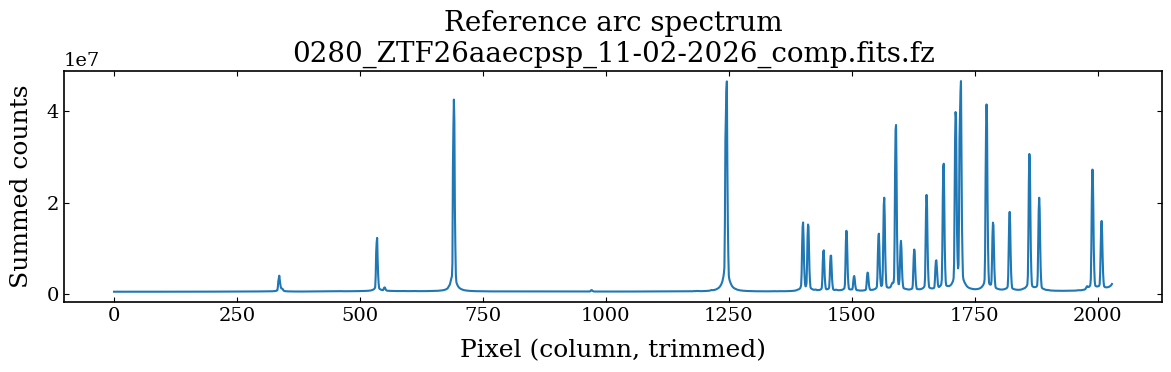

In [51]:
import random

reference_file = random.choice(list(arc_spectra.keys()))
reference_spec = arc_spectra[reference_file]

print("Reference file:", reference_file)
print("Reference spectrum shape:", reference_spec.shape)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(reference_spec)
plt.xlabel("Pixel (column, trimmed)")
plt.ylabel("Summed counts")
plt.title(f"Reference arc spectrum\n{os.path.basename(reference_file)}")
plt.tight_layout()
plt.show()

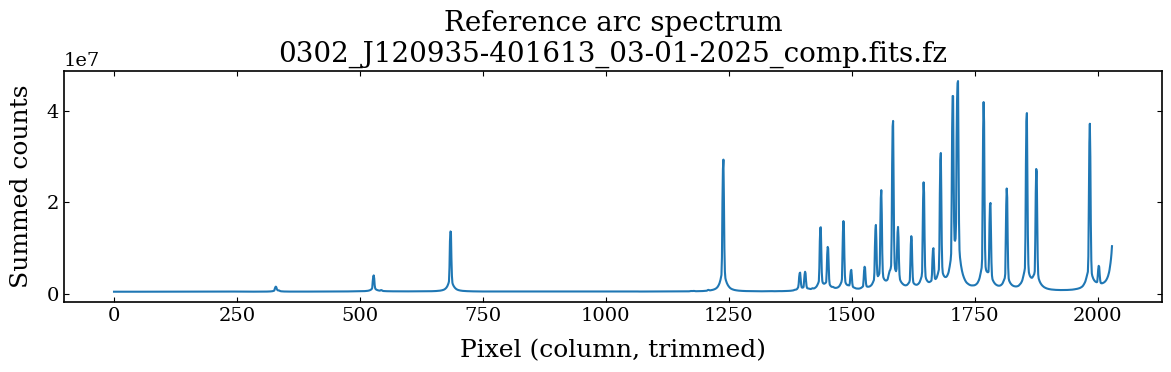

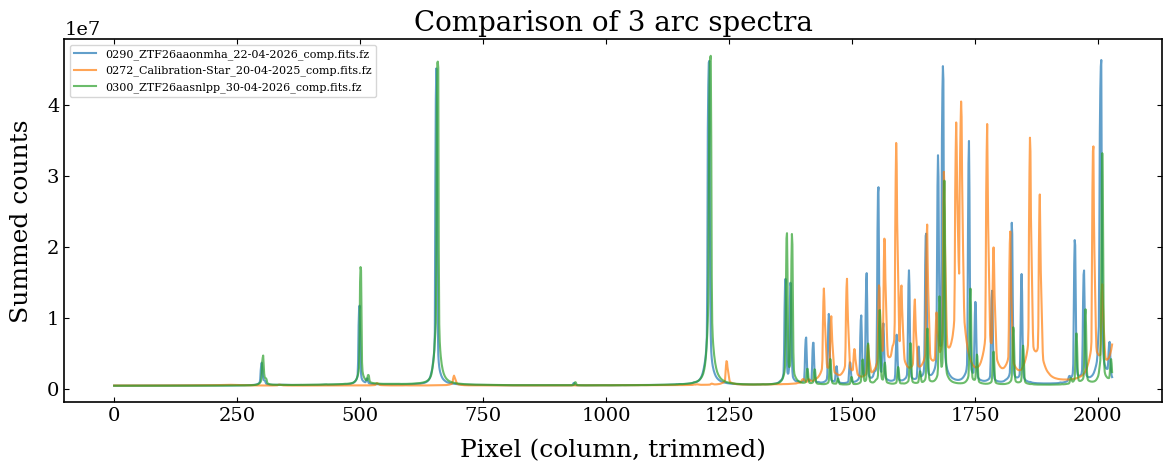

In [49]:
test_files = random.sample(list(arc_spectra.keys()), 3)

plt.figure(figsize=(12, 5))
for f in test_files:
    plt.plot(arc_spectra[f], label=os.path.basename(f), alpha=0.7)

plt.xlabel("Pixel (column, trimmed)")
plt.ylabel("Summed counts")
plt.title("Comparison of 3 arc spectra")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [52]:
from scipy.signal import correlate, correlation_lags

def compute_delta_x(spec, reference_spec):
    """
    Cross-correlates a spectrum against the reference spectrum and
    returns the pixel lag at the correlation peak.
    
    Inputs:
        spec: 1D numpy array, the spectrum to compare
        reference_spec: 1D numpy array, the reference spectrum
    Outputs:
        delta_x: pixel lag at which correlation is maximized
    """
    spec_sub = spec - np.median(spec)
    ref_sub = reference_spec - np.median(reference_spec)
    
    corr = correlate(spec_sub, ref_sub, mode="full")
    lags = correlation_lags(len(spec_sub), len(ref_sub), mode="full")
    
    delta_x = lags[np.argmax(corr)]
    return delta_x

In [53]:
test_delta = compute_delta_x(arc_spectra[test_files[1]], reference_spec)
print("Delta x for", os.path.basename(test_files[1]), ":", test_delta)

Delta x for 0272_Calibration-Star_20-04-2025_comp.fits.fz : 1


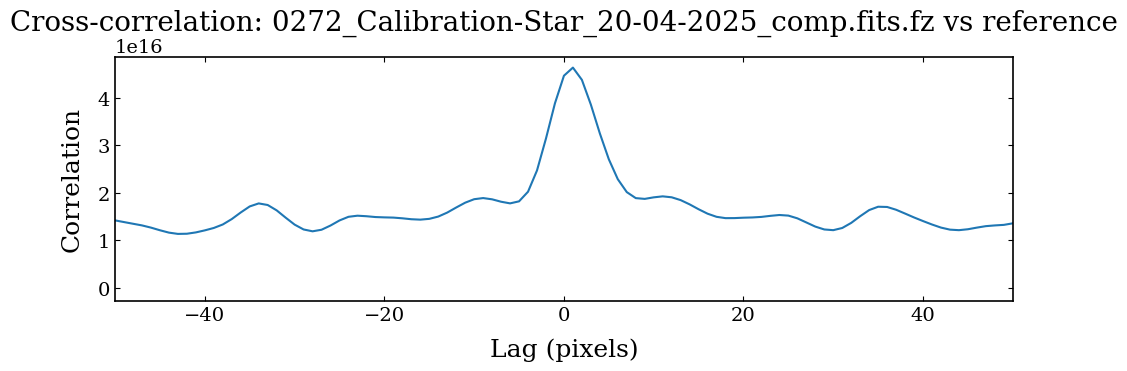

In [54]:
spec_sub = arc_spectra[test_files[1]] - np.median(arc_spectra[test_files[1]])
ref_sub = reference_spec - np.median(reference_spec)

corr = correlate(spec_sub, ref_sub, mode="full")
lags = correlation_lags(len(spec_sub), len(ref_sub), mode="full")

plt.figure(figsize=(10, 4))
plt.plot(lags, corr)
plt.xlabel("Lag (pixels)")
plt.ylabel("Correlation")
plt.title(f"Cross-correlation: {os.path.basename(test_files[1])} vs reference")
plt.xlim(-50, 50)
plt.tight_layout()
plt.show()

In [55]:
def calculate_cross_correlation_shifts(arc_spectra: dict, reference_spec: np.ndarray) -> dict:
    """
    Calculates cross-correlation shifts for all arc spectra relative to a single reference spectrum.

    Inputs:
        arc_spectra: dict mapping filepath -> 1D spectrum array
        reference_spec: 1D reference spectrum array
    Outputs:
        results: dict mapping filepath -> {"dx": int, "confidence": float}
    """
    logger.info(f"Starting cross-correlation shift calculation for {len(arc_spectra)} files...")

    ref_sub = reference_spec - np.median(reference_spec)
    results = {}

    for filepath, spectrum in arc_spectra.items():
        try:
            spec_sub = spectrum - np.median(spectrum)

            correlation = correlate(spec_sub, ref_sub, mode='full')
            lags = correlation_lags(len(spec_sub), len(ref_sub), mode='full')

            best_idx = np.argmax(correlation)
            shift_pixels = lags[best_idx]

            norm_factor = np.sqrt(np.sum(spec_sub**2) * np.sum(ref_sub**2))
            confidence_score = correlation[best_idx] / norm_factor

            results[filepath] = {"dx": shift_pixels, "confidence": confidence_score}

            logger.info(f"  {os.path.basename(filepath)} — Shift: {shift_pixels} px | Confidence: {confidence_score:.4f}")

        except Exception as e:
            logger.error(f"Failed to process file {filepath}: {e}")
            results[filepath] = {"dx": np.nan, "confidence": np.nan}

    logger.info("Finished calculating all dx shifts.")
    return results

In [56]:
single_result = calculate_cross_correlation_shifts({test_files[1]: arc_spectra[test_files[1]]}, reference_spec)
print(single_result)

[INFO at 2026-09-02 20:50:50,428] — Starting cross-correlation shift calculation for 1 files...
[INFO at 2026-09-02 20:50:50,430] —   0272_Calibration-Star_20-04-2025_comp.fits.fz — Shift: 1 px | Confidence: 0.8070
[INFO at 2026-09-02 20:50:50,432] — Finished calculating all dx shifts.


{'/hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0272_Calibration-Star_20-04-2025_comp.fits.fz': {'dx': 1, 'confidence': 0.807038006334309}}


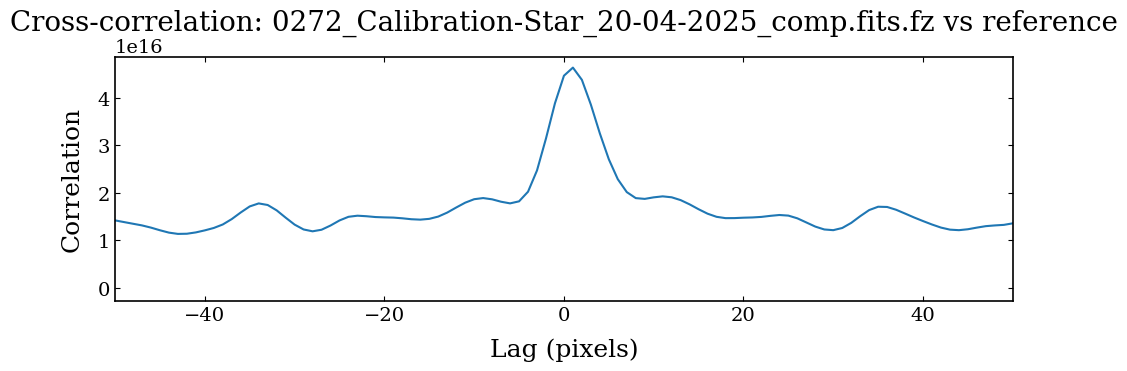

In [57]:
spec_sub = arc_spectra[test_files[1]] - np.median(arc_spectra[test_files[1]])
ref_sub = reference_spec - np.median(reference_spec)

correlation = correlate(spec_sub, ref_sub, mode="full")
lags = correlation_lags(len(spec_sub), len(ref_sub), mode="full")

plt.figure(figsize=(10, 4))
plt.plot(lags, correlation)
plt.xlabel("Lag (pixels)")
plt.ylabel("Correlation")
plt.title(f"Cross-correlation: {os.path.basename(test_files[1])} vs reference")
plt.xlim(-50, 50)
plt.tight_layout()
plt.show()

In [62]:
all_results = calculate_cross_correlation_shifts(arc_spectra, reference_spec)

dx_values = {f: r["dx"] for f, r in all_results.items() if not np.isnan(r["dx"])}
sorted_by_dx = sorted(dx_values.items(), key=lambda x: abs(x[1]), reverse=True)

print("Top 5 largest |dx| shifts:")
for f, dx in sorted_by_dx[:5]:
    print(f"  {os.path.basename(f)} — dx: {dx} px | confidence: {all_results[f]['confidence']:.4f}")

[INFO at 2026-09-02 20:58:49,548] — Starting cross-correlation shift calculation for 555 files...
[INFO at 2026-09-02 20:58:49,549] —   0061_Calibration-Star_13-07-2025_comp.fits.fz — Shift: 5 px | Confidence: 0.8737
[INFO at 2026-09-02 20:58:49,551] —   0062_Calibration-Star_24-01-2025_comp.fits.fz — Shift: -10 px | Confidence: 0.8281
[INFO at 2026-09-02 20:58:49,552] —   0174_Calibration-Star_02-05-2025_comp.fits.fz — Shift: -26 px | Confidence: 0.6316
[INFO at 2026-09-02 20:58:49,554] —   0174_Calibration-Star_18-07-2025_comp.fits.fz — Shift: -24 px | Confidence: 0.6986
[INFO at 2026-09-02 20:58:49,555] —   0174_Calibration-Star_21-06-2025_comp.fits.fz — Shift: -23 px | Confidence: 0.6960
[INFO at 2026-09-02 20:58:49,556] —   0174_Calibration-Star_23-05-2025_comp.fits.fz — Shift: -29 px | Confidence: 0.6543
[INFO at 2026-09-02 20:58:49,558] —   0174_Calibration-Star_27-03-2025_comp.fits.fz — Shift: -49 px | Confidence: 0.6381
[INFO at 2026-09-02 20:58:49,559] —   0174_Calibration-St

Top 5 largest |dx| shifts:
  0248_Calibration-Star_12-09-2025_comp.fits.fz — dx: -359 px | confidence: 0.1560
  0189_Calibration-Star_17-02-2026_comp.fits.fz — dx: -96 px | confidence: 0.7576
  0203_ZTF26aaffxis_17-02-2026_comp.fits.fz — dx: -78 px | confidence: 0.7696
  0204_ZTF26aaffxis_17-02-2026_comp.fits.fz — dx: -78 px | confidence: 0.7816
  0205_ZTF26aaffxis_17-02-2026_comp.fits.fz — dx: -78 px | confidence: 0.7562


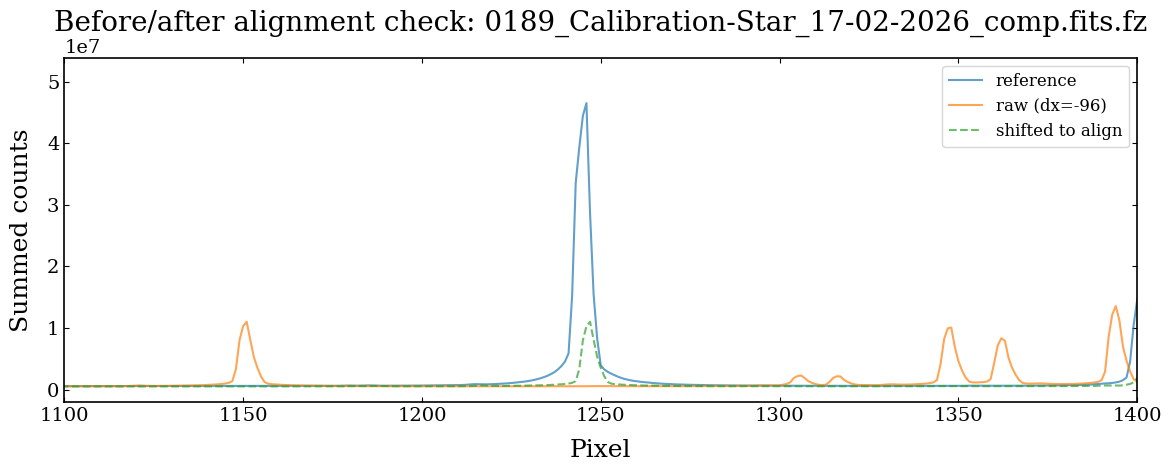

In [60]:
test_file = "/hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0189_Calibration-Star_17-02-2026_comp.fits.fz"
test_spec = arc_spectra[test_file]
test_dx = all_results[test_file]["dx"]

shifted_spec = np.roll(test_spec, -test_dx)

plt.figure(figsize=(12, 5))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec, label=f"raw (dx={test_dx})", alpha=0.7)
plt.plot(shifted_spec, label="shifted to align", alpha=0.7, linestyle="--")
plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Before/after alignment check: {os.path.basename(test_file)}")
plt.xlim(1100, 1400)
plt.tight_layout()
plt.show()

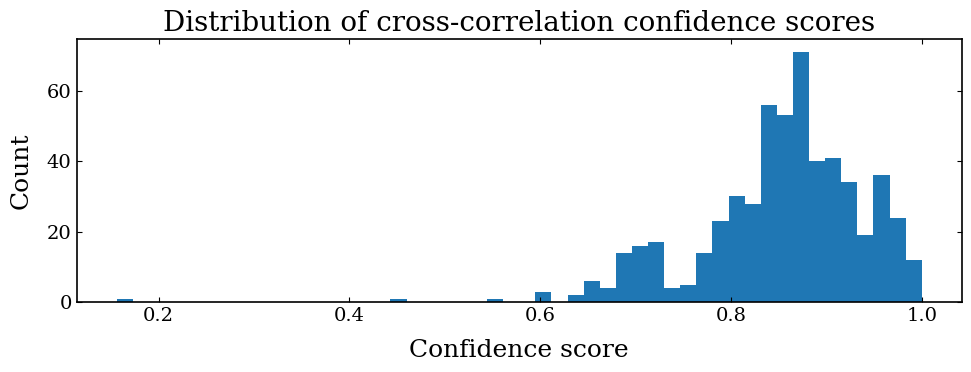

Min: 0.1559807628960833
Max: 0.9999999999999993
Median: 0.8645609300597851
5th percentile: 0.6914768969313886
10th percentile: 0.7210003740466021


In [63]:
confidences = np.array([r["confidence"] for r in all_results.values() if not np.isnan(r["confidence"])])

plt.figure(figsize=(10, 4))
plt.hist(confidences, bins=50)
plt.xlabel("Confidence score")
plt.ylabel("Count")
plt.title("Distribution of cross-correlation confidence scores")
plt.tight_layout()
plt.show()

print("Min:", confidences.min())
print("Max:", confidences.max())
print("Median:", np.median(confidences))
print("5th percentile:", np.percentile(confidences, 5))
print("10th percentile:", np.percentile(confidences, 10))

In [64]:
CONFIDENCE_THRESHOLD = 0.8

filtered_results = {
    f: r for f, r in all_results.items()
    if not np.isnan(r["confidence"]) and r["confidence"] > CONFIDENCE_THRESHOLD
}

print(f"Kept {len(filtered_results)}/{len(all_results)} files after confidence cut (> {CONFIDENCE_THRESHOLD})")

Kept 439/555 files after confidence cut (> 0.8)


In [65]:
sorted_by_dx = sorted(filtered_results.items(), key=lambda x: abs(x[1]["dx"]), reverse=True)

print("Top 5 largest |dx| shifts (confidence > 0.8):")
for f, r in sorted_by_dx[:5]:
    print(f"  {os.path.basename(f)} — dx: {r['dx']} px | confidence: {r['confidence']:.4f}")

Top 5 largest |dx| shifts (confidence > 0.8):
  0320_Calibration-Star_14-02-2026_comp.fits.fz — dx: -78 px | confidence: 0.8717
  0251_Calibration-Star_27-02-2026_comp.fits.fz — dx: -72 px | confidence: 0.8231
  0251_Calibration-Star_24-02-2026_comp.fits.fz — dx: -47 px | confidence: 0.8350
  0251_Calibration-Star_18-04-2026_comp.fits.fz — dx: -43 px | confidence: 0.8215
  0288_ZTF26aaudbym_08-05-2026_comp.fits.fz — dx: -39 px | confidence: 0.8636


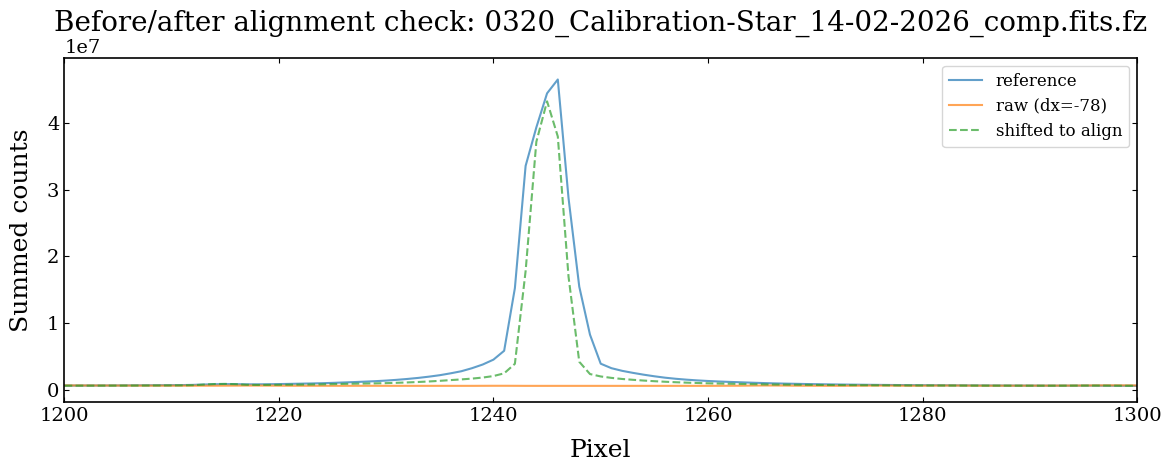

In [ ]:
test_file = "/hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0320_Calibration-Star_14-02-2026_comp.fits.fz"
test_spec = arc_spectra[test_file]
test_dx = filtered_results[test_file]["dx"]

shifted_spec = np.roll(test_spec, -test_dx)

plt.figure(figsize=(12, 5))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec, label=f"raw (dx={test_dx})", alpha=0.7)
plt.plot(shifted_spec, label="shifted to align", alpha=0.7, linestyle="--")
plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Before/after alignment check: {os.path.basename(test_file)}")
plt.xlim(1000, 1300)
plt.tight_layout()
plt.show()

TypeError: unsupported operand type(s) for +: 'int' and 'NoneType'

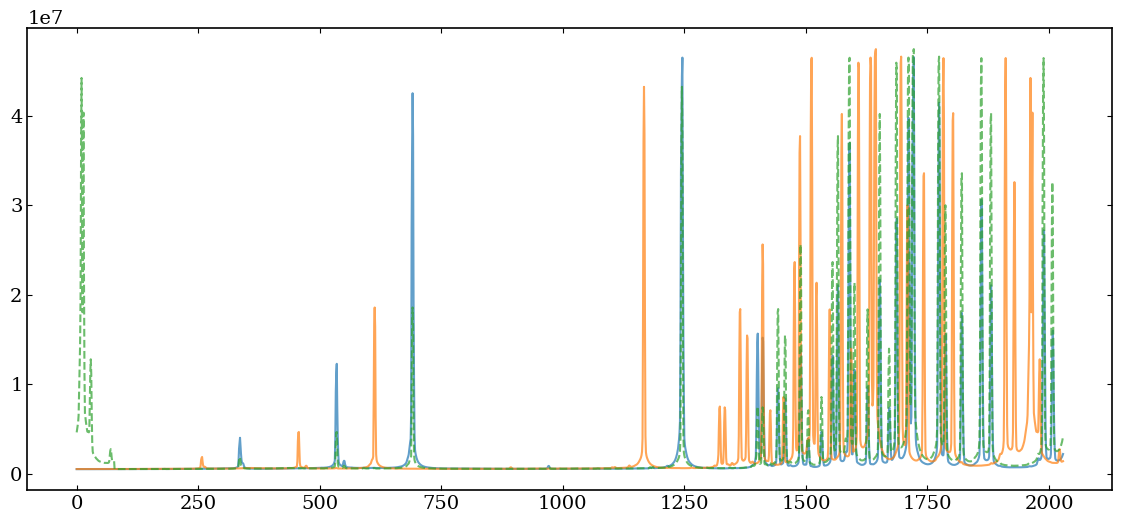

In [68]:
from scipy.signal import find_peaks

plt.figure(figsize=(14, 6))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec, label=f"raw (dx={test_dx})", alpha=0.7)
plt.plot(shifted_spec, label="shifted to align", alpha=0.7, linestyle="--")

# Find prominent peaks in the reference spectrum within this window, to mark them
window_lo, window_hi = None, None
ref_window = reference_spec[window_lo:window_hi]
peaks, _ = find_peaks(ref_window, height=np.max(ref_window) * 0.1, distance=10)
peak_positions = peaks + window_lo

for p in peak_positions:
    plt.axvline(p, color="gray", linestyle=":", alpha=0.5)

plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Before/after alignment check: {os.path.basename(test_file)}")
plt.xlim(window_lo, window_hi)
plt.tight_layout()
plt.show()

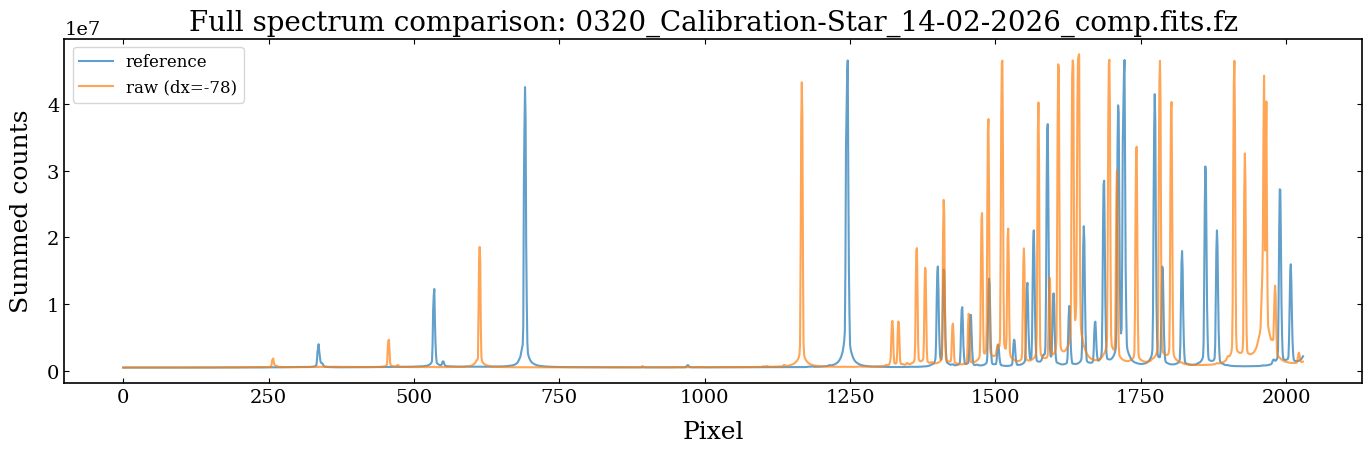

In [69]:
plt.figure(figsize=(14, 5))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec, label=f"raw (dx={test_dx})", alpha=0.7)
plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Full spectrum comparison: {os.path.basename(test_file)}")
plt.tight_layout()
plt.show()

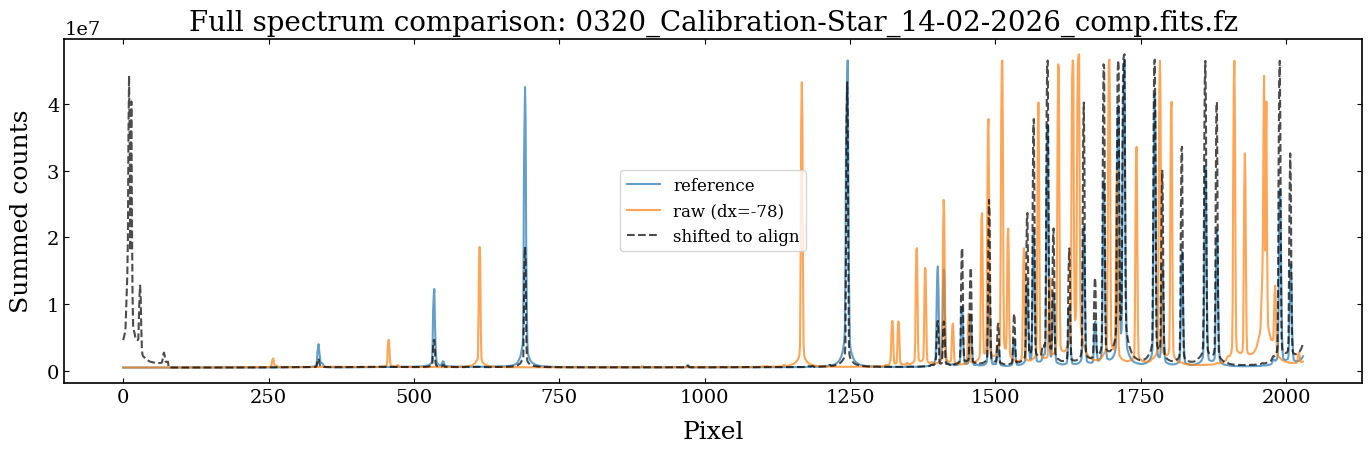

In [70]:
plt.figure(figsize=(14, 5))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec, label=f"raw (dx={test_dx})", alpha=0.7)
plt.plot(shifted_spec, label="shifted to align", color="black", alpha=0.7, linestyle="--")
plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Full spectrum comparison: {os.path.basename(test_file)}")
plt.tight_layout()
plt.show()

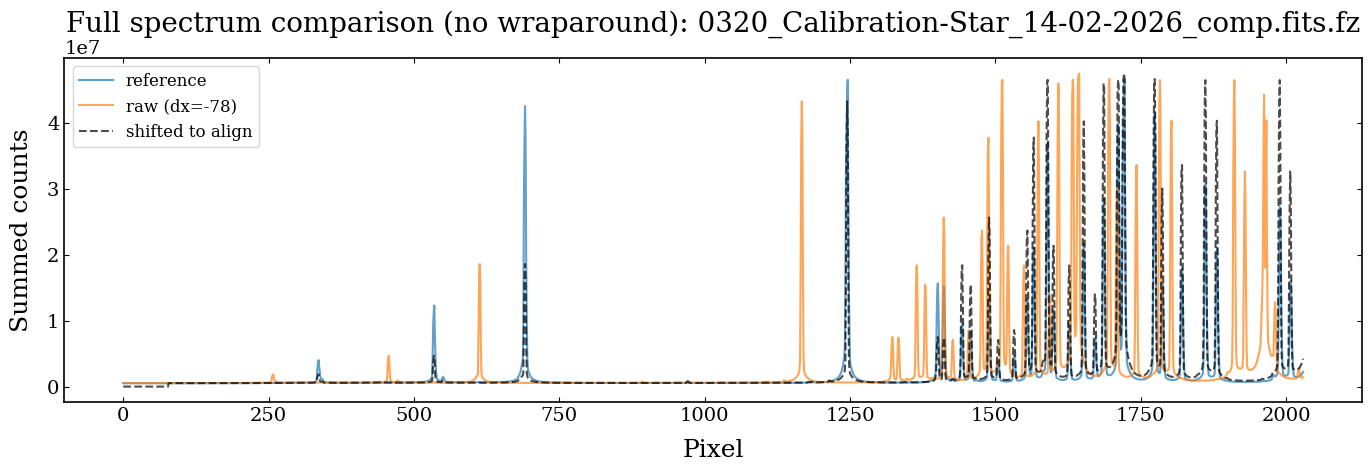

In [71]:
def shift_spectrum(spec, dx):
    """
    Shifts a 1D spectrum by dx pixels, padding with zeros instead of
    wrapping around (unlike np.roll).
    """
    shifted = np.zeros_like(spec)
    if dx > 0:
        shifted[dx:] = spec[:-dx]
    elif dx < 0:
        shifted[:dx] = spec[-dx:]
    else:
        shifted = spec.copy()
    return shifted

shifted_spec_clean = shift_spectrum(test_spec, -test_dx)

plt.figure(figsize=(14, 5))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec, label=f"raw (dx={test_dx})", alpha=0.7)
plt.plot(shifted_spec_clean, label="shifted to align", color="black", alpha=0.7, linestyle="--")
plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Full spectrum comparison (no wraparound): {os.path.basename(test_file)}")
plt.tight_layout()
plt.show()

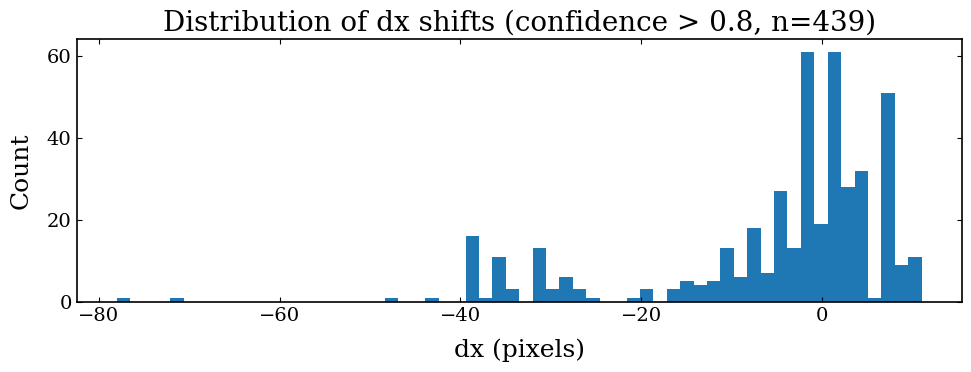

Min: -78
Max: 11
Median: -1.0


In [72]:
dx_values_filtered = [r["dx"] for r in filtered_results.values()]

plt.figure(figsize=(10, 4))
plt.hist(dx_values_filtered, bins=60)
plt.xlabel("dx (pixels)")
plt.ylabel("Count")
plt.title(f"Distribution of dx shifts (confidence > {CONFIDENCE_THRESHOLD}, n={len(dx_values_filtered)})")
plt.tight_layout()
plt.show()

print("Min:", min(dx_values_filtered))
print("Max:", max(dx_values_filtered))
print("Median:", np.median(dx_values_filtered))

In [73]:
DX_THRESHOLD = 20

final_results = {
    f: r for f, r in filtered_results.items()
    if abs(r["dx"]) < DX_THRESHOLD
}

print(f"Kept {len(final_results)}/{len(filtered_results)} files after |dx| < {DX_THRESHOLD} cut")
print(f"(started with {len(all_results)} total files)")

Kept 374/439 files after |dx| < 20 cut
(started with 555 total files)


In [74]:
sorted_final = sorted(final_results.items(), key=lambda x: abs(x[1]["dx"]), reverse=True)

print("Top 5 largest |dx| shifts (confidence > 0.8, |dx| < 20):")
for f, r in sorted_final[:5]:
    print(f"  {os.path.basename(f)} — dx: {r['dx']} px | confidence: {r['confidence']:.4f}")

Top 5 largest |dx| shifts (confidence > 0.8, |dx| < 20):
  0272_Calibration-Star_24-02-2025_comp.fits.fz — dx: -16 px | confidence: 0.8054
  0289_2025ahoe_08-01-2026_comp.fits.fz — dx: -16 px | confidence: 0.8280
  0290_2025ahoe_08-01-2026_comp.fits.fz — dx: -16 px | confidence: 0.8602
  0248_Calibration-Star_08-01-2026_comp.fits.fz — dx: -15 px | confidence: 0.8237
  0267_Calibration-Star_22-05-2026_comp.fits.fz — dx: -15 px | confidence: 0.8121


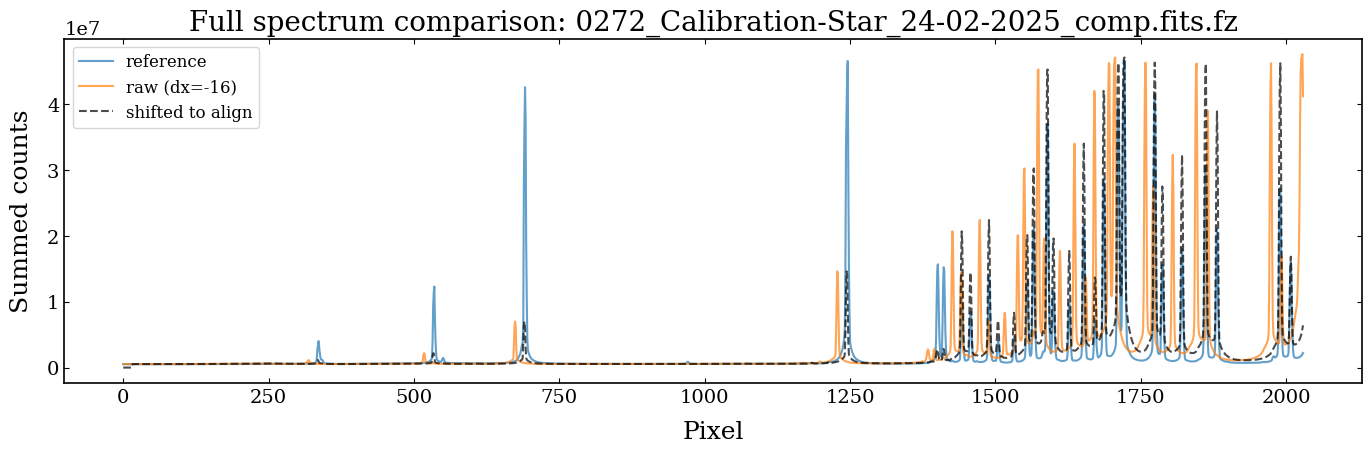

In [75]:
test_file2 = "/hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis/0272_Calibration-Star_24-02-2025_comp.fits.fz"
test_spec2 = arc_spectra[test_file2]
test_dx2 = final_results[test_file2]["dx"]

shifted_spec2 = shift_spectrum(test_spec2, -test_dx2)

plt.figure(figsize=(14, 5))
plt.plot(reference_spec, label="reference", alpha=0.7)
plt.plot(test_spec2, label=f"raw (dx={test_dx2})", alpha=0.7)
plt.plot(shifted_spec2, label="shifted to align", color="black", alpha=0.7, linestyle="--")
plt.xlabel("Pixel")
plt.ylabel("Summed counts")
plt.legend()
plt.title(f"Full spectrum comparison: {os.path.basename(test_file2)}")
plt.tight_layout()
plt.show()

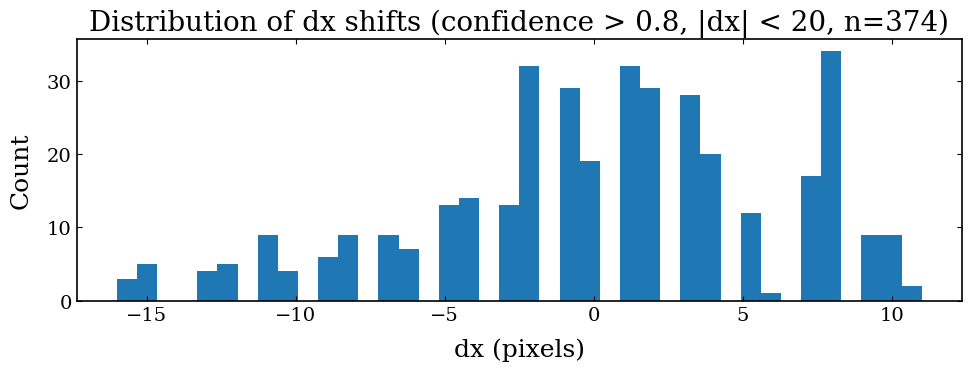

Min: -16
Max: 11
Median: 1.0


In [76]:
dx_values_final = [r["dx"] for r in final_results.values()]

plt.figure(figsize=(10, 4))
plt.hist(dx_values_final, bins=40)
plt.xlabel("dx (pixels)")
plt.ylabel("Count")
plt.title(f"Distribution of dx shifts (confidence > {CONFIDENCE_THRESHOLD}, |dx| < {DX_THRESHOLD}, n={len(dx_values_final)})")
plt.tight_layout()
plt.show()

print("Min:", min(dx_values_final))
print("Max:", max(dx_values_final))
print("Median:", np.median(dx_values_final))

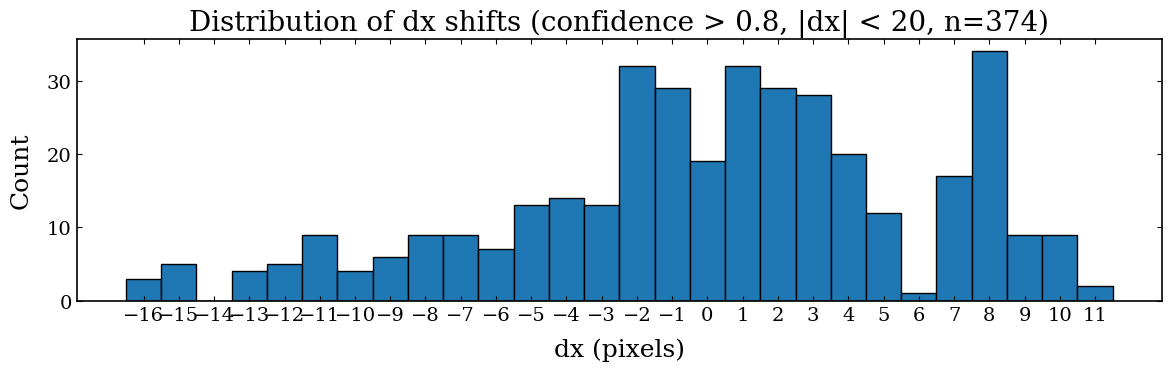

In [77]:
dx_values_final = np.array([r["dx"] for r in final_results.values()])

bins = np.arange(dx_values_final.min() - 0.5, dx_values_final.max() + 1.5, 1)

plt.figure(figsize=(12, 4))
plt.hist(dx_values_final, bins=bins, edgecolor="black")
plt.xlabel("dx (pixels)")
plt.ylabel("Count")
plt.title(f"Distribution of dx shifts (confidence > {CONFIDENCE_THRESHOLD}, |dx| < {DX_THRESHOLD}, n={len(dx_values_final)})")
plt.xticks(np.arange(dx_values_final.min(), dx_values_final.max() + 1, 1))
plt.tight_layout()
plt.show()

In [11]:
def read_fits_file(file: str) -> tuple:
    """
    Reads a FITS file and returns a merged header and data dictionary.
    - header: merged across all HDUs (later HDUs overwrite earlier ones on duplicate keys)
    - data: dict of {hdu_index: data_array} for all HDUs
    """
    with fits.open(file) as hdul:
        header = hdul[0].header
        for i in range(1, len(hdul)):
            header.update(hdul[i].header)
        data = {i: hdul[i].data for i in range(len(hdul))}
    return header, data

    
def find_lamp_type(header: dict) -> str:

    # From the file headers, these are all the lamps available.
    lamp_mapping = {
        "LAMP_HGA": "HgAr",
        "LAMP_NE": "Ne",
        "LAMP_AR": "Ar",
        "LAMP_FE": "Fe",
        "LAMP_CU": "Cu",
        "LAMP_QUA": "Quartz",
    }

    # the heaker key hwere the value is True, is the lamp turned on. So I am considering only those lamps that are turned on, and making a tuple of their names. This step is added to identify what was the lamp that was used for the arc.
    Lamps = tuple(
        name 
        for kw, name in lamp_mapping.items() 
        if header.get(kw) in [True, "TRUE", "T"]
    )

    # if multple lamps are on, join them with a +, for example: HgAr+Ne
    lamp_str = "+".join(Lamps) if Lamps else "Unknown"

    return lamp_str

In [12]:
def build_arc_groups(good_files: list, 
                    valid_gratings: tuple = ("400_M1", "400_M2")
                    ) -> tuple[list[dict], defaultdict]:
    """
    Reads metadata from a list of arc FITS files and groups them by date, object, and grating.

    Inputs:
        good_files: list of file paths (output of filter_fits_files)
        valid_gratings: tuple of grating names to keep
    Outputs:
        metadata: list of metadata dicts, one per file
        groups: nested defaultdict grouped as groups[date][object][grating] -> list of entries
    """

    # creating a list of metadata dicts, one per file, that contains all the relevant information we need for our analysis, such as date, object, grating, lamp type.
    metadata = []
    for good_file in good_files:
        header, data = read_fits_file(good_file)
        lamp = find_lamp_type(header)
        filename = os.path.basename(good_file)
        file_path = os.path.dirname(good_file)

        metadata.append({
            "filename": filename,
            "file_path": file_path,
            "date": header['DATE'],
            "obs_datetime": header["DATE-OBS"],
            "grating": header['WAVMODE'],
            "lamps": lamp,
            "object": header.get("OBJECT", "N/A"),
        })

    # Now, with all the existing metadata, I am grouping the files in the following order: data -> object -> grating. This will give me a nested disctionary. The values will be lists of metadata entries that correspond to each combination of date, object, and grating. This grouping will allow me to easily access and analyze the arcs based on these criteria, which is important for understanding any patterns or trends in the data related to the mask slip issue.
    groups = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))
    for entry in metadata:
        grating = entry["grating"]
        if grating in valid_gratings:
            logger.info(f"Grouping file: {entry['filename']} — Date: {entry['date']}, OBJECT: {entry['object']}, Grating: {grating}")
            groups[entry["date"]][entry["object"]][grating].append(entry)
        else:
            logger.warning(f"Skipping file with unexpected grating: {entry['filename']} — Grating: {grating}")

    return metadata, groups

In [13]:
arcs_metadata_pre, arc_groups   = build_arc_groups(good_arcs)

[WARNING at 2026-09-02 17:43:56,040] — Skipping file with unexpected grating: 0002_Calibration-Star_13-04-2025_comp.fits.fz — Grating: 2100_6507A
[WARNING at 2026-09-02 17:43:56,041] — Skipping file with unexpected grating: 0003_Calibration-Star_13-04-2025_comp.fits.fz — Grating: 1200_CaNIR
[WARNING at 2026-09-02 17:43:56,043] — Skipping file with unexpected grating: 0006_Calibration-Star_13-04-2025_comp.fits.fz — Grating: 1200_CaNIR_6300A
[INFO at 2026-09-02 17:43:56,045] — Grouping file: 0061_Calibration-Star_13-07-2025_comp.fits.fz — Date: 2025-07-13, OBJECT: HR5501, Grating: 400_M1
[INFO at 2026-09-02 17:43:56,047] — Grouping file: 0062_Calibration-Star_13-07-2025_comp.fits.fz — Date: 2025-07-13, OBJECT: HR5501, Grating: 400_M2
[INFO at 2026-09-02 17:43:56,048] — Grouping file: 0062_Calibration-Star_24-01-2025_comp.fits.fz — Date: 2025-01-24, OBJECT: HR1996, Grating: 400_M1
[INFO at 2026-09-02 17:43:56,050] — Grouping file: 0063_Calibration-Star_24-01-2025_comp.fits.fz — Date: 2025

In [14]:
table = Table(title="Arc Group Summary")
table.add_column("Maintenance Status", style="cyan")
table.add_column("Number of Groups",   style="magenta", justify="right")
table.add_column("Median Files/Group", style="green",   justify="right")

for groups, label in [(arc_groups, "Pre-Maintenance")]:
    group_sizes = []
    for date in groups:
        for obj in groups[date]:
            for grating in groups[date][obj]:
                group_sizes.append(len(groups[date][obj][grating]))

    n_groups     = len(group_sizes)
    median_files = np.median(group_sizes) if group_sizes else 0

    table.add_row(label, str(n_groups), f"{median_files:.1f}")

Console().print(table)

                      Arc Group Summary                       
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Maintenance Status ┃ Number of Groups ┃ Median Files/Group ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ Pre-Maintenance    │              391 │                1.0 │
└────────────────────┴──────────────────┴────────────────────┘

In [17]:
groups

defaultdict(<function __main__.build_arc_groups.<locals>.<lambda>()>,
            {'2025-07-13': defaultdict(<function __main__.build_arc_groups.<locals>.<lambda>.<locals>.<lambda>()>,
                         {'HR5501': defaultdict(list,
                                      {'400_M1': [{'filename': '0061_Calibration-Star_13-07-2025_comp.fits.fz',
                                         'file_path': '/hickory/proj/andreonilab/users/anirudhs/data/soar/mask_analysis',
                                         'date': '2025-07-13',
                                         'obs_datetime': '2025-07-13T23:01:53.148',
                                         'grating': '400_M1',
                                         'lamps': 'HgAr+Ne',
                                         'object': 'HR5501'}],
                                       '400_M2': [{'filename': '0062_Calibration-Star_13-07-2025_comp.fits.fz',
                                         'file_path': '/hickory/proj/andreonilab/u